#Tests for .in files

##MSD visualizer

34 organelles, 1861 frames, lag up to 3106.2 tau
membrane        n =   1  alpha = 0.936  D_sim = 0.0004768 r_c^2/tau
nucleus         n =   1  alpha = 0.927  D_sim = 0.0009126 r_c^2/tau
mitochondrion   n =  12  alpha = 1.020  D_sim = 0.002678 r_c^2/tau
vesicle         n =  20  alpha = 0.932  D_sim = 0.004328 r_c^2/tau


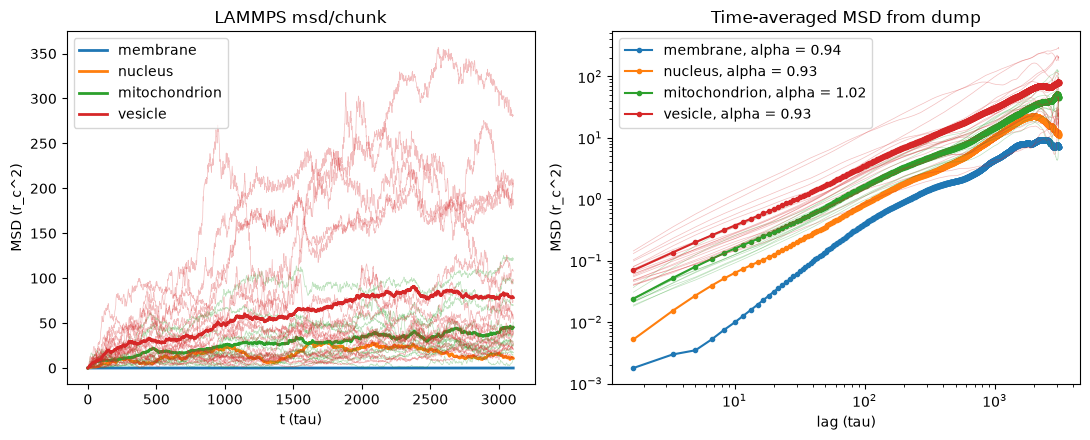

In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from utilities import read_msd_dat, msd_time_averaged, fit_power_law, read_type_names, read_dump_com_typed

# The notebook runs from DPD tissue/code
CODE_DIR = Path.cwd()
RUN_DIR = CODE_DIR / "runs/cell_2"
GRAPHS_DIR = CODE_DIR.parent / "graphs"

DT = 0.01        # must match `timestep` in the input script

# Settings
run = RUN_DIR    # run folder with msd_mito.dat and dump.m1
RC_UM = 0.25     # bead size r_c in micrometres
FIT_FROM = 0.01   # fit lags above this fraction of the longest lag
TAU_S = None     # DPD time unit in seconds (after calibration)

from utilities import read_msd_dat, msd_time_averaged, fit_power_law, read_type_names, read_dump_com_typed

NAME = "cell"   # in_name you gave Run(...)

names = read_type_names(run / f"{NAME}.data")
steps, msd_lmp = read_msd_dat(run / "msd_org.dat")
t_lmp = steps * DT
dsteps, com, mol_ids, types = read_dump_com_typed(run / f"dump.{NAME}")
lags, msd_all, per_org = msd_time_averaged(com)
t = lags * (dsteps[1] - dsteps[0]) * DT
late = t >= FIT_FROM * t[-1]
msd_lmp = msd_lmp[:, mol_ids - 1]   # chunk ID = molecule ID, so columns line up with com

print(f"{com.shape[1]} organelles, {len(dsteps)} frames, lag up to {t[-1]:.1f} tau")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
results = {}
for k, ty in enumerate(np.unique(types)):
    sel = types == ty
    name, color = names.get(ty, f"type {ty}"), f"C{k}"
    msd = per_org[:, sel].mean(axis=1)
    alpha, _ = fit_power_law(t[late], msd[late])
    D_sim = np.polyfit(t[late], msd[late], 1)[0] / 6
    results[name] = (alpha, D_sim)
    line = f"{name:15s} n = {sel.sum():3d}  alpha = {alpha:.3f}  D_sim = {D_sim:.4g} r_c^2/tau"
    if TAU_S:
        line += f"  D = {D_sim * RC_UM**2 / TAU_S:.4g} um^2/s"
    print(line)
    ax[0].plot(t_lmp, msd_lmp[:, sel], color=color, lw=0.5, alpha=0.3)
    ax[0].plot(t_lmp, msd_lmp[:, sel].mean(axis=1), color=color, lw=2, label=name)
    ax[1].loglog(t, per_org[:, sel], color=color, lw=0.5, alpha=0.3)
    ax[1].loglog(t, msd, "o-", color=color, ms=3, label=f"{name}, alpha = {alpha:.2f}")
ax[0].set(xlabel="t (tau)", ylabel="MSD (r_c^2)", title="LAMMPS msd/chunk")
ax[1].set(xlabel="lag (tau)", ylabel="MSD (r_c^2)", title="Time-averaged MSD from dump")
ax[0].legend(); ax[1].legend()
fig.tight_layout()
GRAPHS_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(GRAPHS_DIR / f"{NAME}_msd.png", dpi=150)

###No membrane

In [ ]:
from utilities import Run, Type

run = Run("test_run", "m1_crowded_mix", [40, 40, 8])
run.add_type(Type("mitochondrion", 12, "capsule", r=1.0, l=8.0, rel_density=1.1))
run.add_type(Type("vesicle", 20, "sphere", r=1.0, rel_density=1.05, a_cyto=35.0))
run.fill_cytoplasm(3.0)
run.write_data_file()
run.write_input_file(steps=200000, dump_every=1000, thermo_every=1000)

###With membrane

In [ ]:
from utilities import Run, Type

run = Run("runs/cell", "cell", BOX=[24, 24, 24])
run.add_type(Type("membrane", 1, "shell", r=10.0, a_cyto=50.0))  
run.add_type(Type("nucleus", 1, "sphere", r=4.0, rel_density=1.10, a_cyto=40.0))
run.add_type(Type("mitochondrion", 12, "capsule", r=1.0, l=8.0, rel_density=1.1))
run.add_type(Type("vesicle", 20, "sphere", r=1.0, rel_density=1.05, a_cyto=35.0))
run.fill_cytoplasm(RHO=3)
run.write_data_file()
run.write_input_file()

###Fat globules

In [ ]:
from utilities import Run, Type
import numpy as np

kT, eta = 1.380649e-23 * 295, 4.0           # J, Pa s
def D_um2_s(d_um):                           # Stokes-Einstein, d = diameter in um
    return kT / (6 * np.pi * eta * d_um / 2 * 1e-6) * 1e12

run = Run("provolone_run", "provolone", [50, 50, 50])
sizes = [("fat_10um", 10.0, 40, 1.0), ("fat_3um", 3.0, 100, 0.5), ("fat_1um", 1.0, 400, 0.5)]
for name, d, n, s in sizes:                  # big ones first so they fit
    run.add_type(Type(name, n, "sphere", r=d / 2, s=s))
run.fill_cytoplasm(0.0)                      # no solvent beads; this just sets run.cyto to empty
run.write_data_file()
for t, (_, d, _, _) in zip(run.types, sizes):
    n_beads = len(t.beads(t.positions[0]))
    print(t.atom_type, t.name, "D =", D_um2_s(d), "bead mass =", 1.0 * 0.1 / D_um2_s(d) / n_beads)
run.write_input_file(steps=100000, dump_every=1000, thermo_every=1000)

2 fat_10um D = 1.0803741390390045e-05 bead mass = 17.97291792399551
3 fat_3um D = 3.6012471301300145e-05 bead mass = 22.57573836794558
4 fat_1um D = 0.00010803741390390043 bead mass = 132.2293247265384


###Cell msd

34 objects, 251 frames, lag up to 500.0 tau, fit 6.0-124.0 tau
nucleus         n =   1  alpha = 0.996  D_sim = 0.001499 r_c^2/tau
mitochondrion   n =  12  alpha = 1.163  D_sim = 0.009224 r_c^2/tau
vesicle         n =  20  alpha = 0.928  D_sim = 0.009917 r_c^2/tau
cell drift             alpha = 1.399  (removed from the curves above)


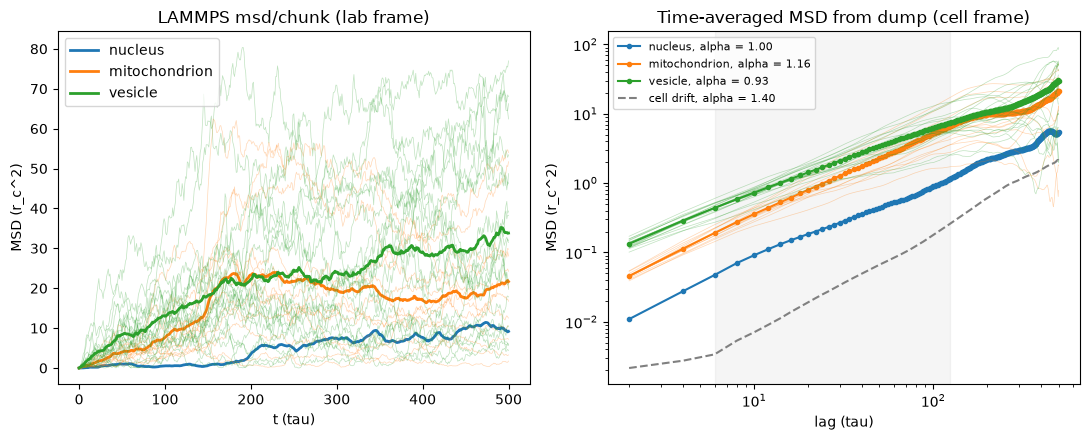

In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from utilities import read_msd_dat, msd_time_averaged, fit_power_law, read_type_names, read_dump_com_typed

# The notebook runs from DPD tissue/code
CODE_DIR = Path.cwd()
GRAPHS_DIR = CODE_DIR.parent / "graphs"

# Settings
NAME = "cell"                # in_name you gave Run(...)
run = CODE_DIR / "runs/cell" # run folder with msd_org.dat, dump.<NAME> and <NAME>.data
DT = 0.01                    # must match `timestep` in the input script
RC_UM = 0.25                 # bead size r_c in micrometres
FIT_FROM = 0.01              # fit lags above this fraction of the longest lag
FIT_TO = 0.25                # ...and below this fraction (few time origins beyond it)
TAU_S = None                 # DPD time unit in seconds (after calibration)

names = read_type_names(run / f"{NAME}.data")
steps, msd_lmp = read_msd_dat(run / "msd_org.dat")
t_lmp = steps * DT
dsteps, com, mol_ids, types = read_dump_com_typed(run / f"dump.{NAME}")
msd_lmp = msd_lmp[:, mol_ids - 1]   # chunk ID = molecule ID, so columns line up with com

# Cell frame: subtract the membrane's centre of mass so the cell's own drift is removed
mem_ty = next((k for k, v in names.items() if v == "membrane"), None)
drift = None
if mem_ty is not None:
    cell = com[:, types == mem_ty]                      # (frames, 1, 3)
    _, drift, _ = msd_time_averaged(cell)
    com = com - cell
lags, msd_all, per_org = msd_time_averaged(com)
t = lags * (dsteps[1] - dsteps[0]) * DT
fit = (t >= FIT_FROM * t[-1]) & (t <= FIT_TO * t[-1])

print(f"{com.shape[1]} objects, {len(dsteps)} frames, lag up to {t[-1]:.1f} tau, fit {t[fit][0]:.1f}-{t[fit][-1]:.1f} tau")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
results = {}
for k, ty in enumerate(ty for ty in np.unique(types) if ty != mem_ty):
    sel = types == ty
    name, color = names.get(ty, f"type {ty}"), f"C{k}"
    msd = per_org[:, sel].mean(axis=1)
    alpha, _ = fit_power_law(t[fit], msd[fit])
    D_sim = np.polyfit(t[fit], msd[fit], 1)[0] / 6
    results[name] = (alpha, D_sim)
    line = f"{name:15s} n = {sel.sum():3d}  alpha = {alpha:.3f}  D_sim = {D_sim:.4g} r_c^2/tau"
    if TAU_S:
        line += f"  D = {D_sim * RC_UM**2 / TAU_S:.4g} um^2/s"
    print(line)
    ax[0].plot(t_lmp, msd_lmp[:, sel], color=color, lw=0.5, alpha=0.3)
    ax[0].plot(t_lmp, msd_lmp[:, sel].mean(axis=1), color=color, lw=2, label=name)
    ax[1].loglog(t, per_org[:, sel], color=color, lw=0.5, alpha=0.3)
    ax[1].loglog(t, msd, "o-", color=color, ms=3, label=f"{name}, alpha = {alpha:.2f}")
if drift is not None:
    a_cell, _ = fit_power_law(t[fit], drift[fit])
    print(f"{'cell drift':15s}        alpha = {a_cell:.3f}  (removed from the curves above)")
    ax[1].loglog(t, drift, "--", color="gray", label=f"cell drift, alpha = {a_cell:.2f}")
for a in ax:
    a.axvspan(t[fit][0], t[fit][-1], color="gray", alpha=0.08) if a is ax[1] else None
ax[0].set(xlabel="t (tau)", ylabel="MSD (r_c^2)", title="LAMMPS msd/chunk (lab frame)")
ax[1].set(xlabel="lag (tau)", ylabel="MSD (r_c^2)", title="Time-averaged MSD from dump (cell frame)")
ax[0].legend(); ax[1].legend(fontsize=8)
fig.tight_layout()
GRAPHS_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(GRAPHS_DIR / f"{NAME}_msd.png", dpi=150)


dropped 60 frames (120.0 tau), 191 frames kept, lag up to 190.0 tau
sections (tau): [2, 4.97]  [4.97, 12.4]  [12.4, 30.7]  [30.7, 76.4]  [76.4, 190]
membrane        does not move in this frame, skipped
nucleus         n =   1  alpha: nan  1.16  0.89  1.05  0.85
mitochondrion   n =  12  alpha: nan  1.22  1.14  0.74  0.72
vesicle         n =  20  alpha: nan  0.99  0.92  0.85  0.72


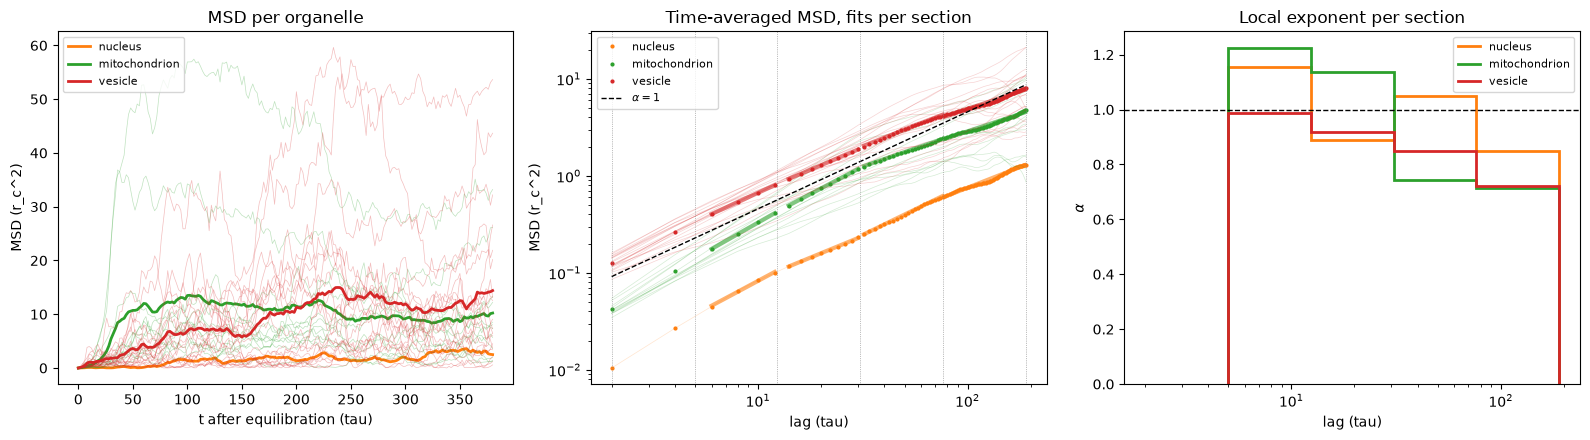

In [3]:
from tile_sample import EQUIL_FRAMES     # 60 frames (300 s), the same frames the hologram sampling throws away

N_SECTIONS = 5        # log-spaced lag windows, one alpha per window
MAX_LAG_FRAC = 0.5    # longest lag used, as a fraction of the post-equilibrium length (few time origins beyond it)

# Drop the equilibration frames and restart the clock at the first kept frame
dt_frame = (dsteps[1] - dsteps[0]) * DT
com_eq = com[EQUIL_FRAMES:]
t_abs = (dsteps[EQUIL_FRAMES:] - dsteps[EQUIL_FRAMES]) * DT
msd_abs = ((com_eq - com_eq[0])**2).sum(axis=2)           # (frames, organelles), single time origin

# Time-averaged MSD on the kept frames only
lags, _, per_org_eq = msd_time_averaged(com_eq)
t_eq = lags * dt_frame
keep = t_eq <= MAX_LAG_FRAC * t_eq[-1]
t_eq, per_org_eq = t_eq[keep], per_org_eq[keep]

# Section edges, evenly spaced in log(lag)
edges = np.logspace(np.log10(t_eq[0]), np.log10(t_eq[-1]), N_SECTIONS + 1)
sections = [(t_eq >= a) & (t_eq <= b) for a, b in zip(edges[:-1], edges[1:])]

print(f"dropped {EQUIL_FRAMES} frames ({EQUIL_FRAMES * dt_frame:.1f} tau), "
      f"{len(com_eq)} frames kept, lag up to {t_eq[-1]:.1f} tau")
print("sections (tau): " + "  ".join(f"[{a:.3g}, {b:.3g}]" for a, b in zip(edges[:-1], edges[1:])))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
alpha_sections = {}
for k, ty in enumerate(np.unique(types)):
    sel = types == ty
    name, color = names.get(ty, f"type {ty}"), f"C{k}"
    msd = per_org_eq[:, sel].mean(axis=1)
    if np.all(msd <= 0):                  # e.g. the membrane after subtracting its own centre of mass
        print(f"{name:15s} does not move in this frame, skipped")
        continue

    # Power-law fit inside each section, drawn on top of the data
    alphas = []
    for m in sections:
        m = m & (msd > 0)                  # same points fit_power_law keeps (also drops NaN)
        if m.sum() < 3:
            alphas.append(np.nan)
            continue
        a, c = fit_power_law(t_eq[m], msd[m])
        alphas.append(a)
        ax[1].loglog(t_eq[m], c * t_eq[m]**a, color=color, lw=3, alpha=0.6)
    alpha_sections[name] = np.array(alphas)
    print(f"{name:15s} n = {sel.sum():3d}  alpha: " + "  ".join(f"{a:.2f}" for a in alphas))

    ax[0].plot(t_abs, msd_abs[:, sel], color=color, lw=0.5, alpha=0.3)
    ax[0].plot(t_abs, msd_abs[:, sel].mean(axis=1), color=color, lw=2, label=name)
    ax[1].loglog(t_eq, per_org_eq[:, sel], color=color, lw=0.5, alpha=0.2)
    ax[1].loglog(t_eq, msd, "o", color=color, ms=2, label=name)
    ax[2].stairs(alpha_sections[name], edges, color=color, lw=2, label=name)

# alpha = 1 guide through the mean MSD at the shortest lag (moving objects only), and the section boundaries
moving = per_org_eq[0] > 0
m0 = per_org_eq[0, moving].mean()
ax[1].loglog(t_eq, m0 * t_eq / t_eq[0], "k--", lw=1, label=r"$\alpha = 1$")
for e in edges:
    ax[1].axvline(e, color="gray", lw=0.5, ls=":")
ax[2].axhline(1, color="k", ls="--", lw=1)
ax[2].set_xscale("log")

ax[0].set(xlabel="t after equilibration (tau)", ylabel="MSD (r_c^2)", title="MSD per organelle")
ax[1].set(xlabel="lag (tau)", ylabel="MSD (r_c^2)", title="Time-averaged MSD, fits per section")
ax[2].set(xlabel="lag (tau)", ylabel=r"$\alpha$", title="Local exponent per section")
for a in ax:
    a.legend(fontsize=8)
fig.tight_layout()
fig.savefig(GRAPHS_DIR / f"{NAME}_msd_sections.png", dpi=150)

###Runs for tiled sample

In [1]:
from utilities import Run, Type

N_RUNS = 4
TAU_S = 3.0           # seconds per DPD time unit (pilot calibration, D_mito = 1e-4 um^2/s)
DT = 0.01             # timestep in tau
FRAME_S = 5.0         # EAFIT: one hologram every 5 s (0.2 Hz)
RECORD_S = 7000.0     # 1400 holograms
N_DELAYS = 20         # delay slots per run
DELAY_S = 100.0       # spacing between delay slots, > a few correlation times
EQUIL_S = 300.0       # thrown away at the start

steps_per_frame = round(FRAME_S / TAU_S / DT)
n_frames = round((EQUIL_S + RECORD_S + N_DELAYS * DELAY_S) / FRAME_S)
steps = steps_per_frame * n_frames

import sys
if "test" in sys.argv:                       # quick check: tiny run
    steps_per_frame, steps = 20, 200

for k in range(N_RUNS):
    run = Run(f"runs/cell_{k}", "cell", BOX=[24, 24, 24], rng=100 + k)    # different placement per run
    run.add_type(Type("membrane", 1, "shell", r=10.0, a_cyto=50.0))
    run.add_type(Type("nucleus", 1, "sphere", r=4.0, rel_density=1.10, a_cyto=40.0))
    run.add_type(Type("mitochondrion", 12, "capsule", r=1.0, l=8.0, rel_density=1.1))
    run.add_type(Type("vesicle", 20, "sphere", r=1.0, rel_density=1.05, a_cyto=35.0))
    run.fill_cytoplasm(RHO=3)
    run.write_data_file()
    run.write_input_file(dt=DT, steps=steps, dump_every=steps_per_frame, msd_every=steps_per_frame,
                         thermo_every=10 * steps_per_frame, seed=34387 + 10 * k,
                         dump_group="membrane org")
print(f"{steps} steps per run, one frame every {steps_per_frame} steps")

310620 steps per run, one frame every 167 steps


###Compress dump files into npz

In [1]:
from utilities import compress_dump

for k in range(4):
    compress_dump(f"runs/cell_{k}")

In [9]:
#Load the trajectories and build the circle:
import numpy as np
from tile_sample import build_layout, frame_positions, tiles_in_square, RECORD_FRAMES
trajs = [dict(np.load(f"runs/cell_{k}/traj.npz")) for k in range(4)]
print(len(trajs[0]["steps"]), "frames per run (need 1840)")

layout = build_layout(n_runs=4, diam_um=1000, seed=0)   # change diam_um for another size
np.savez("layout.npz", **layout)                        # later: layout = dict(np.load("layout.npz"))
print(len(layout["run"]), "tiles")

1861 frames per run (need 1840)
21821 tiles


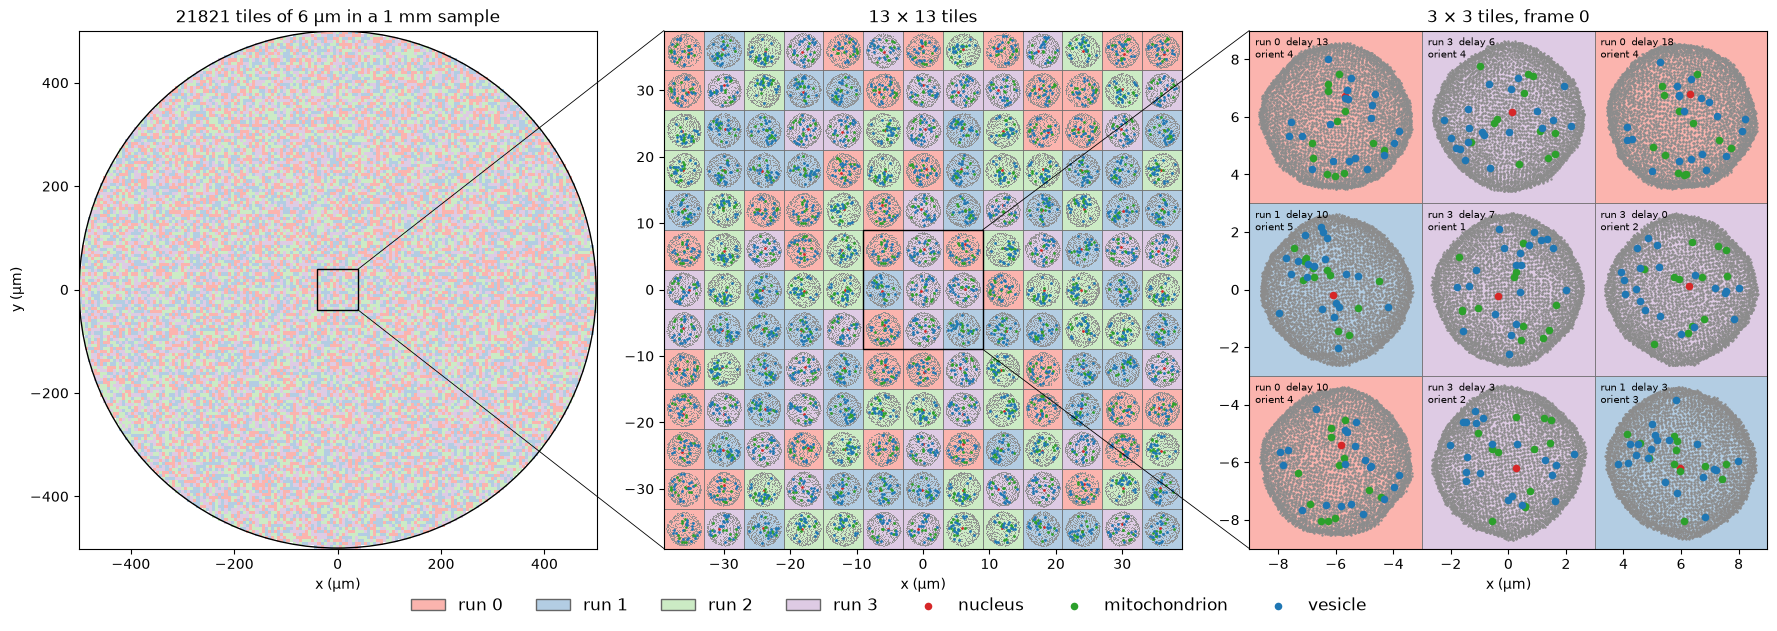

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.patches import Rectangle, Circle, ConnectionPatch
from matplotlib.colors import ListedColormap
from tile_sample import frame_positions, BOX_RC, RC_UM

K = 0                 # recording frame to show
N1, N2 = 6, 1         # zoom half-widths in tiles: 13 x 13 tiles, then 3 x 3 tiles
L = BOX_RC * RC_UM    # tile size (6 um)
h1, h2 = (N1 + 0.5) * L, (N2 + 0.5) * L     # zoom half-widths in um, on tile edges

run_cmap = ListedColormap(plt.cm.Pastel1.colors[:len(trajs)])
org_color = {"nucleus": "C3", "mitochondrion": "C2", "vesicle": "C0"}
c = layout["centre_um"]

# Whole sample as an image: one pixel per tile, coloured by run (outside the circle stays transparent)
ij = np.rint(c / L).astype(int)
n = np.abs(ij).max()
grid = np.full((2 * n + 1, 2 * n + 1), np.nan)
grid[ij[:, 1] + n, ij[:, 0] + n] = layout["run"]

def draw_tiles(ax, tiles, label=False):
    """Tile squares coloured by run, optionally labelled with run, delay and orientation."""
    for t in tiles:
        cx, cy = c[t]
        ax.add_patch(Rectangle((cx - L/2, cy - L/2), L, L, fc=run_cmap(layout["run"][t]),
                               ec="0.4", lw=0.5, zorder=0))
        if label:
            ax.text(cx - L/2 + 0.2, cy + L/2 - 0.2,
                    f"run {layout['run'][t]}  delay {layout['delay'][t]}\norient {layout['orient'][t]}",
                    fontsize=7, va="top")

def draw_sample(ax, tiles, stride, ms):
    """Membrane beads in grey and organelle centres coloured by type, at frame K."""
    m = frame_positions(layout, trajs, K, part="mem", tiles=tiles, stride=stride)
    ax.scatter(m[:, 0], m[:, 1], s=ms / 10, c="0.55", lw=0, zorder=1)
    r = frame_positions(layout, trajs, K, tiles=tiles)
    ty = np.concatenate([trajs[layout["run"][t]]["type_names"] for t in tiles])
    for name, col in org_color.items():
        sel = ty == name
        ax.scatter(r[sel, 0], r[sel, 1], s=ms, c=col, lw=0, label=name, zorder=2)

def zoom_box(ax_from, ax_to, h):
    """Square of half-width h on ax_from, joined to the edges of ax_to."""
    ax_from.add_patch(Rectangle((-h, -h), 2 * h, 2 * h, fill=False, ec="k", lw=1, zorder=3))
    for y in (-h, h):
        fig.add_artist(ConnectionPatch((h, y), (-h, y), "data", "data",
                                       axesA=ax_from, axesB=ax_to, color="k", lw=0.6))

tiles1 = np.nonzero((np.abs(c) <= N1 * L + 1e-6).all(axis=1))[0]
tiles2 = np.nonzero((np.abs(c) <= N2 * L + 1e-6).all(axis=1))[0]

fig, ax = plt.subplots(1, 3, figsize=(18, 6.2))

# 1) Whole 1 mm sample
ext = (n + 0.5) * L
ax[0].imshow(grid, origin="lower", extent=[-ext, ext, -ext, ext], cmap=run_cmap,
             vmin=-0.5, vmax=len(trajs) - 0.5, interpolation="nearest")
ax[0].add_patch(Circle((0, 0), 500, fill=False, ec="k", lw=1))
ax[0].set(title=f"{len(c)} tiles of {L:.0f} µm in a 1 mm sample", xlabel="x (µm)", ylabel="y (µm)")

# 2) 13 x 13 tiles: tiling and cells
draw_tiles(ax[1], tiles1)
draw_sample(ax[1], tiles1, stride=10, ms=4)
ax[1].set(xlim=(-h1, h1), ylim=(-h1, h1), title=f"{2*N1 + 1} × {2*N1 + 1} tiles", xlabel="x (µm)")

# 3) 3 x 3 tiles: every membrane bead, and the run / delay / orientation of each tile
draw_tiles(ax[2], tiles2, label=True)
draw_sample(ax[2], tiles2, stride=1, ms=30)
ax[2].set(xlim=(-h2, h2), ylim=(-h2, h2), title=f"{2*N2 + 1} × {2*N2 + 1} tiles, frame {K}", xlabel="x (µm)")

for a in ax:
    a.set_aspect("equal")
zoom_box(ax[0], ax[1], h1)
zoom_box(ax[1], ax[2], h2)

# One legend for runs and organelle types
run_handles = [Rectangle((0, 0), 1, 1, fc=run_cmap(r), ec="0.4") for r in range(len(trajs))]
org_handles, org_labels = ax[2].get_legend_handles_labels()
fig.legend(
    run_handles + org_handles,
    [f"run {r}" for r in range(len(trajs))] + org_labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=len(trajs) + len(org_color),
    frameon=False,
    fontsize=12,
)
fig.tight_layout(rect=(0, 0.10, 1, 1))
fig.savefig(Path("../graphs/tiling.png"), dpi=200)
plt.show()
